<a href="https://colab.research.google.com/github/Asmishan/Exit-Exam/blob/main/ExitExam_Asmishan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [316]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')


from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [317]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [318]:
import pandas as pd
df=pd.read_csv('/content/drive/MyDrive/EXIT EXAM/G3.csv')

In [319]:
df.head()

,enterprise_group_id,display_name,enterprise_group_name,group_root_lei,enterprise_group_jurisdiction,enterprise_group_entity_status,website,company_type,employees,employees_year,...,market_cap_date,legal_units_count,direct_subsidiaries_count,max_hierarchy_depth,is_standalone_entity,website_source,employees_source,revenue_source,net_income_source,market_cap_source
0,EG_03260722,Morgan Stanley,MORGAN STANLEY,IGJSJL3JD5P30I6NJZ34,US-DE,ACTIVE,morganstanley.com,PUBLIC,83000.0,2025.0,...,2025-12-31,1013,173.0,8.0,False,morganstanley.com,sec.gov,sec.gov,sec.gov,finance.yahoo.com
1,EG_03256960,Bank of America,BANK OF AMERICA CORPORATION,9DJT3UXIJIZJI4WXO774,US-DE,ACTIVE,bankofamerica.com,PUBLIC,213000.0,2025.0,...,2025-12-31,761,155.0,5.0,False,bankofamerica.com,sec.gov,sec.gov,https://investor.bankofamerica.com/regulatory-...,macrotrends.net
2,EG_01804232,Citigroup,CITIGROUP INC.,6SHGI4ZSSLCXXQSBB395,US-DE,ACTIVE,citigroup.com,PUBLIC,226000.0,2025.0,...,2025-12-31,742,22.0,9.0,False,citigroup.com,sec.gov,tradingview.com,tradingview.com,uk.finance.yahoo.com
3,EG_02027196,Goldman Sachs,"THE GOLDMAN SACHS GROUP, INC.",784F5XWPLTWKTBV3E584,US-DE,ACTIVE,https://www.goldmansachs.com,PUBLIC,47400.0,2025.0,...,2025-12-31,568,190.0,7.0,False,goldmansachs.com,sec.gov,goldmansachs.com,goldmansachs.com,finance.yahoo.com
4,EG_03266820,Siemens,Siemens Aktiengesellschaft,W38RGI023J3WT1HWRP32,DE,ACTIVE,siemens.com,PUBLIC,318000.0,2025.0,...,2025-09-30,568,454.0,3.0,False,siemens.com,siemens.com,siemens.com,siemens.com,siemens.com


In [320]:
df.shape

(1755, 28)

In [321]:
df.describe()

,employees,employees_year,revenue,revenue_year,net_income,net_income_year,market_cap,legal_units_count,direct_subsidiaries_count,max_hierarchy_depth
count,1.656000e+03,1655.000000,1.654000e+03,1653.000000,1.599000e+03,1599.000000,1.224000e+03,1755.000000,1747.000000,1747.000000
mean,3.989013e+04,2024.951057,9.050901e+11,2024.923775,7.895350e+10,2024.914321,2.057347e+12,34.330484,17.531196,2.038351
std,9.625128e+04,0.312028,1.080451e+13,0.441763,1.216758e+12,0.459405,4.925187e+13,58.980527,27.903769,1.044385
min,0.000000e+00,2023.000000,-3.518000e+09,2012.000000,-1.060000e+12,2012.000000,8.270000e+06,1.000000,0.000000,0.000000
25%,2.521750e+03,2025.000000,2.198500e+09,2025.000000,5.681000e+07,2025.000000,3.600000e+09,11.000000,5.000000,1.000000
50%,1.230000e+04,2025.000000,9.247250e+09,2025.000000,5.889000e+08,2025.000000,1.936500e+10,18.000000,9.000000,2.000000
75%,3.875725e+04,2025.000000,3.478425e+10,2025.000000,3.414500e+09,2025.000000,8.876100e+10,35.000000,18.000000,2.000000
max,2.100000e+06,2026.000000,3.336000e+14,2026.000000,4.520000e+13,2026.000000,1.716780e+15,1013.000000,454.000000,9.000000


In [322]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1755 entries, 0 to 1754
Data columns (total 28 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   enterprise_group_id             1755 non-null   object 
 1   display_name                    1755 non-null   object 
 2   enterprise_group_name           1755 non-null   object 
 3   group_root_lei                  1755 non-null   object 
 4   enterprise_group_jurisdiction   1755 non-null   object 
 5   enterprise_group_entity_status  1755 non-null   object 
 6   website                         1716 non-null   object 
 7   company_type                    1753 non-null   object 
 8   employees                       1656 non-null   float64
 9   employees_year                  1655 non-null   float64
 10  revenue                         1654 non-null   float64
 11  revenue_currency                1654 non-null   object 
 12  revenue_year                    16

In [323]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

Rows: 1755
Columns: 28

Column names:
['enterprise_group_id', 'display_name', 'enterprise_group_name', 'group_root_lei', 'enterprise_group_jurisdiction', 'enterprise_group_entity_status', 'website', 'company_type', 'employees', 'employees_year', 'revenue', 'revenue_currency', 'revenue_year', 'net_income', 'net_income_currency', 'net_income_year', 'market_cap', 'market_cap_currency', 'market_cap_date', 'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth', 'is_standalone_entity', 'website_source', 'employees_source', 'revenue_source', 'net_income_source', 'market_cap_source']


In [324]:
df.dtypes

,0
enterprise_group_id,object
display_name,object
enterprise_group_name,object
group_root_lei,object
enterprise_group_jurisdiction,object
enterprise_group_entity_status,object
website,object
company_type,object
employees,float64
employees_year,float64


In [325]:
TARGET = "revenue"

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

numerical_features = [c for c in numerical_cols if c != TARGET]
categorical_features = categorical_cols.copy()

print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)


Numerical columns:
['employees', 'employees_year', 'revenue', 'revenue_year', 'net_income', 'net_income_year', 'market_cap', 'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth']

Categorical columns:
['enterprise_group_id', 'display_name', 'enterprise_group_name', 'group_root_lei', 'enterprise_group_jurisdiction', 'enterprise_group_entity_status', 'website', 'company_type', 'revenue_currency', 'net_income_currency', 'market_cap_currency', 'market_cap_date', 'is_standalone_entity', 'website_source', 'employees_source', 'revenue_source', 'net_income_source', 'market_cap_source']

Numerical features: ['employees', 'employees_year', 'revenue_year', 'net_income', 'net_income_year', 'market_cap', 'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth']
Categorical features: ['enterprise_group_id', 'display_name', 'enterprise_group_name', 'group_root_lei', 'enterprise_group_jurisdiction', 'enterprise_group_entity_status', 'website', 'company_type', 'revenue

In [326]:
print("Numerical summary statistics:")
display(df[numerical_cols].describe().T)

print("\nCategorical summary statistics:")
display(df[categorical_cols].describe().T)


Numerical summary statistics:


,count,mean,std,min,25%,50%,75%,max
employees,1656.0,3.989013e+04,9.625128e+04,0.000000e+00,2.521750e+03,1.230000e+04,3.875725e+04,2.100000e+06
employees_year,1655.0,2.024951e+03,3.120278e-01,2.023000e+03,2.025000e+03,2.025000e+03,2.025000e+03,2.026000e+03
revenue,1654.0,9.050901e+11,1.080451e+13,-3.518000e+09,2.198500e+09,9.247250e+09,3.478425e+10,3.336000e+14
revenue_year,1653.0,2.024924e+03,4.417632e-01,2.012000e+03,2.025000e+03,2.025000e+03,2.025000e+03,2.026000e+03
net_income,1599.0,7.895350e+10,1.216758e+12,-1.060000e+12,5.681000e+07,5.889000e+08,3.414500e+09,4.520000e+13
net_income_year,1599.0,2.024914e+03,4.594046e-01,2.012000e+03,2.025000e+03,2.025000e+03,2.025000e+03,2.026000e+03
market_cap,1224.0,2.057347e+12,4.925187e+13,8.270000e+06,3.600000e+09,1.936500e+10,8.876100e+10,1.716780e+15
legal_units_count,1755.0,3.433048e+01,5.898053e+01,1.000000e+00,1.100000e+01,1.800000e+01,3.500000e+01,1.013000e+03
direct_subsidiaries_count,1747.0,1.753120e+01,2.790377e+01,0.000000e+00,5.000000e+00,9.000000e+00,1.800000e+01,4.540000e+02
max_hierarchy_depth,1747.0,2.038351e+00,1.044385e+00,0.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00,9.000000e+00



Categorical summary statistics:


,count,unique,top,freq
enterprise_group_id,1755,1755,EG_03260722,1
display_name,1755,1749,Huhtamaki,2
enterprise_group_name,1755,1755,MORGAN STANLEY,1
group_root_lei,1755,1755,IGJSJL3JD5P30I6NJZ34,1
enterprise_group_jurisdiction,1755,104,US-DE,254
enterprise_group_entity_status,1755,1,ACTIVE,1755
website,1716,1711,https://www.lgt.com/,2
company_type,1753,8,PUBLIC,1284
revenue_currency,1654,35,EUR,568
net_income_currency,1599,35,EUR,543


In [327]:
df.isnull().sum()

,0
enterprise_group_id,0
display_name,0
enterprise_group_name,0
group_root_lei,0
enterprise_group_jurisdiction,0
enterprise_group_entity_status,0
website,39
company_type,2
employees,99
employees_year,100


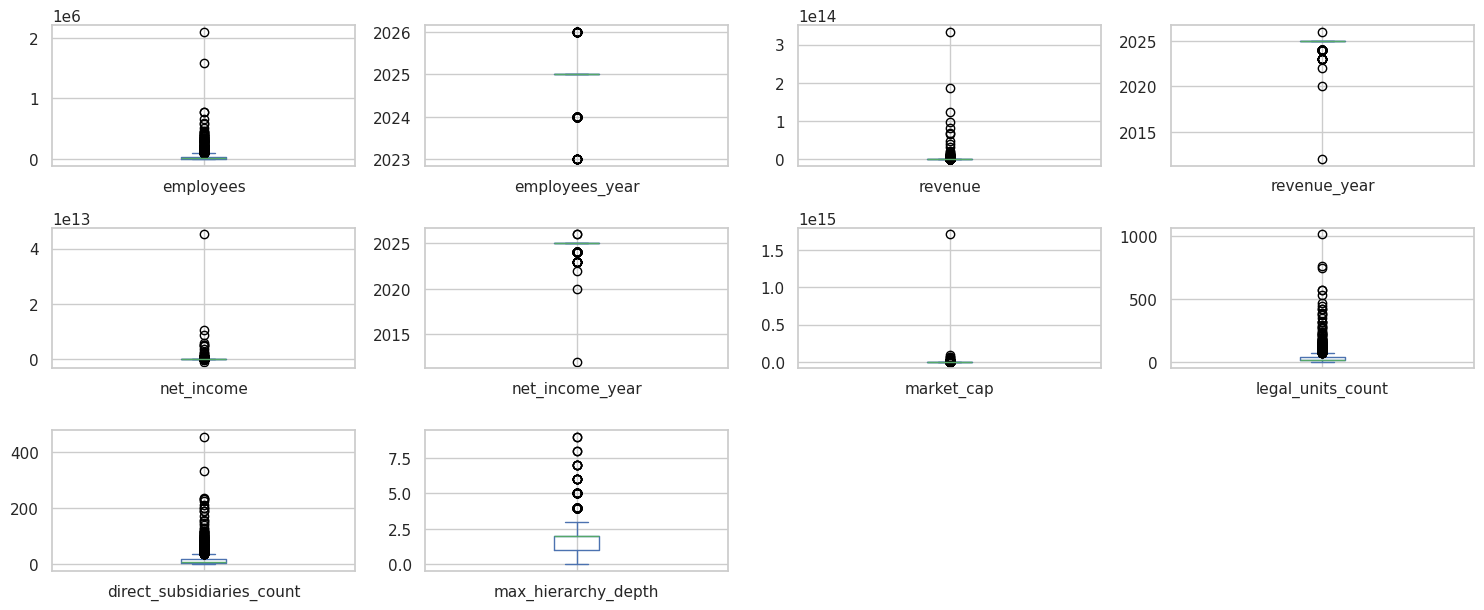

In [328]:
df.select_dtypes(include='number').plot(
    kind='box',
    figsize=(15, 8),
    subplots=True,
    layout=(4, 4),
    sharey=False
)

plt.tight_layout()
plt.show()

Task 1 - Data understanding and exploration

1.The distribution is right skewed

2.Market capitalization , employee net income has strongest relationship

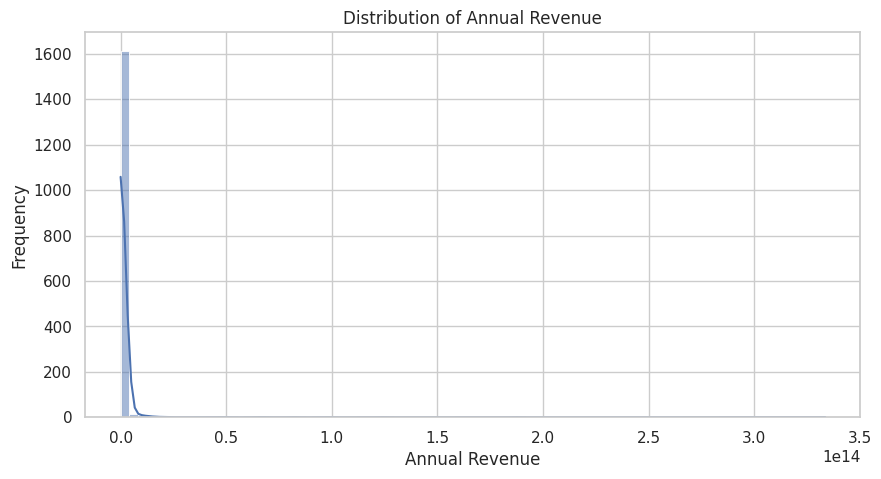

Median revenue: 9247250000.0
Mean revenue: 905090065171.3295


In [329]:
plt.figure(figsize=(10, 5))
sns.histplot(df[TARGET].dropna(), kde=True)
plt.title("Distribution of Annual Revenue")
plt.xlabel("Annual Revenue")
plt.ylabel("Frequency")
plt.show()

print("Median revenue:", df[TARGET].median())
print("Mean revenue:", df[TARGET].mean())


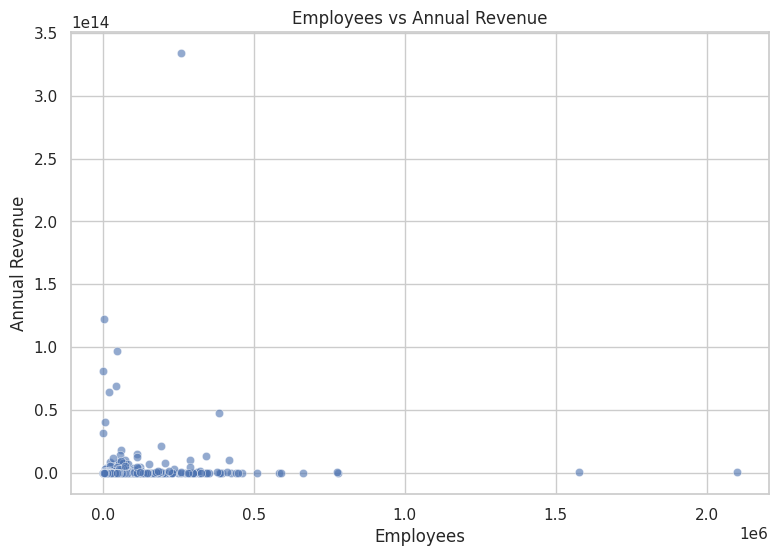

In [330]:
plot_df = df[[ "employees", TARGET ]].dropna()

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="employees", y=TARGET, alpha=0.6)
plt.title("Employees vs Annual Revenue")
plt.xlabel("Employees")
plt.ylabel("Annual Revenue")
plt.show()

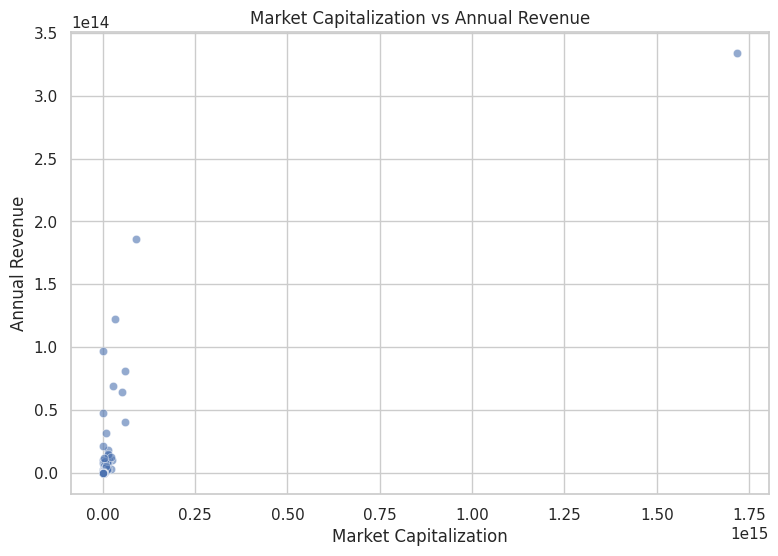

In [331]:
plot_df = df[[ "market_cap", TARGET ]].dropna()

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="market_cap", y=TARGET, alpha=0.6)
plt.title("Market Capitalization vs Annual Revenue")
plt.xlabel("Market Capitalization")
plt.ylabel("Annual Revenue")
plt.show()


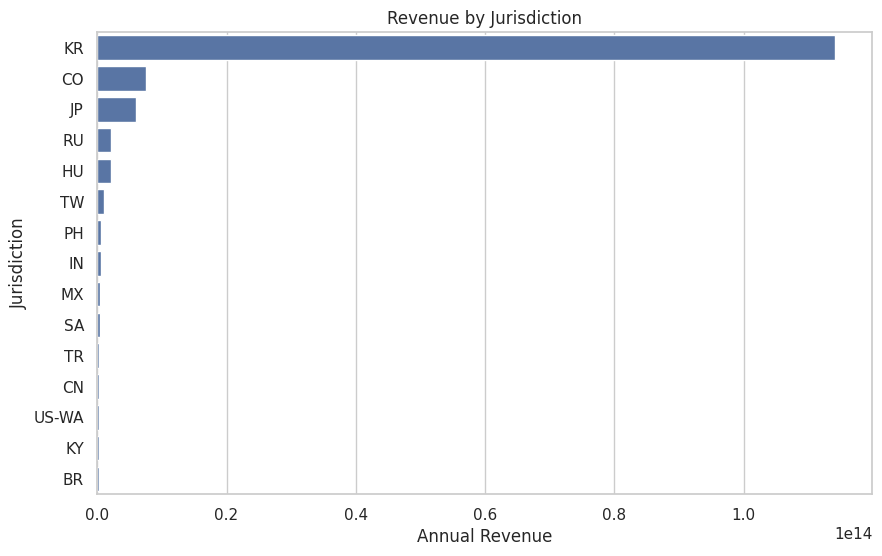

In [332]:
jurisdiction_revenue = (
    df.groupby("enterprise_group_jurisdiction")[TARGET]
      .mean()
      .sort_values(ascending=False)
      .head(15)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=jurisdiction_revenue.values, y=jurisdiction_revenue.index)
plt.title("Revenue by Jurisdiction")
plt.xlabel("Annual Revenue")
plt.ylabel("Jurisdiction")
plt.show()


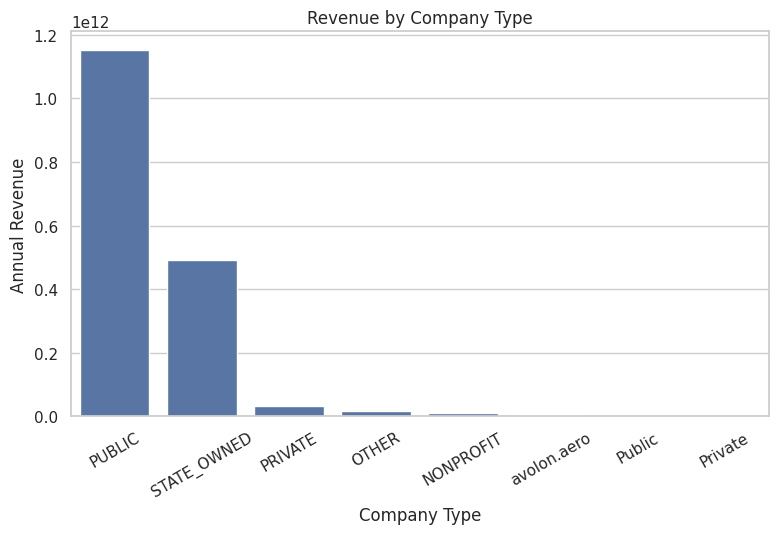

In [333]:
company_revenue = (
    df.groupby("company_type")[TARGET]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=company_revenue.index, y=company_revenue.values)
plt.title("Revenue by Company Type")
plt.xlabel("Company Type")
plt.ylabel("Annual Revenue")
plt.xticks(rotation=30)
plt.show()

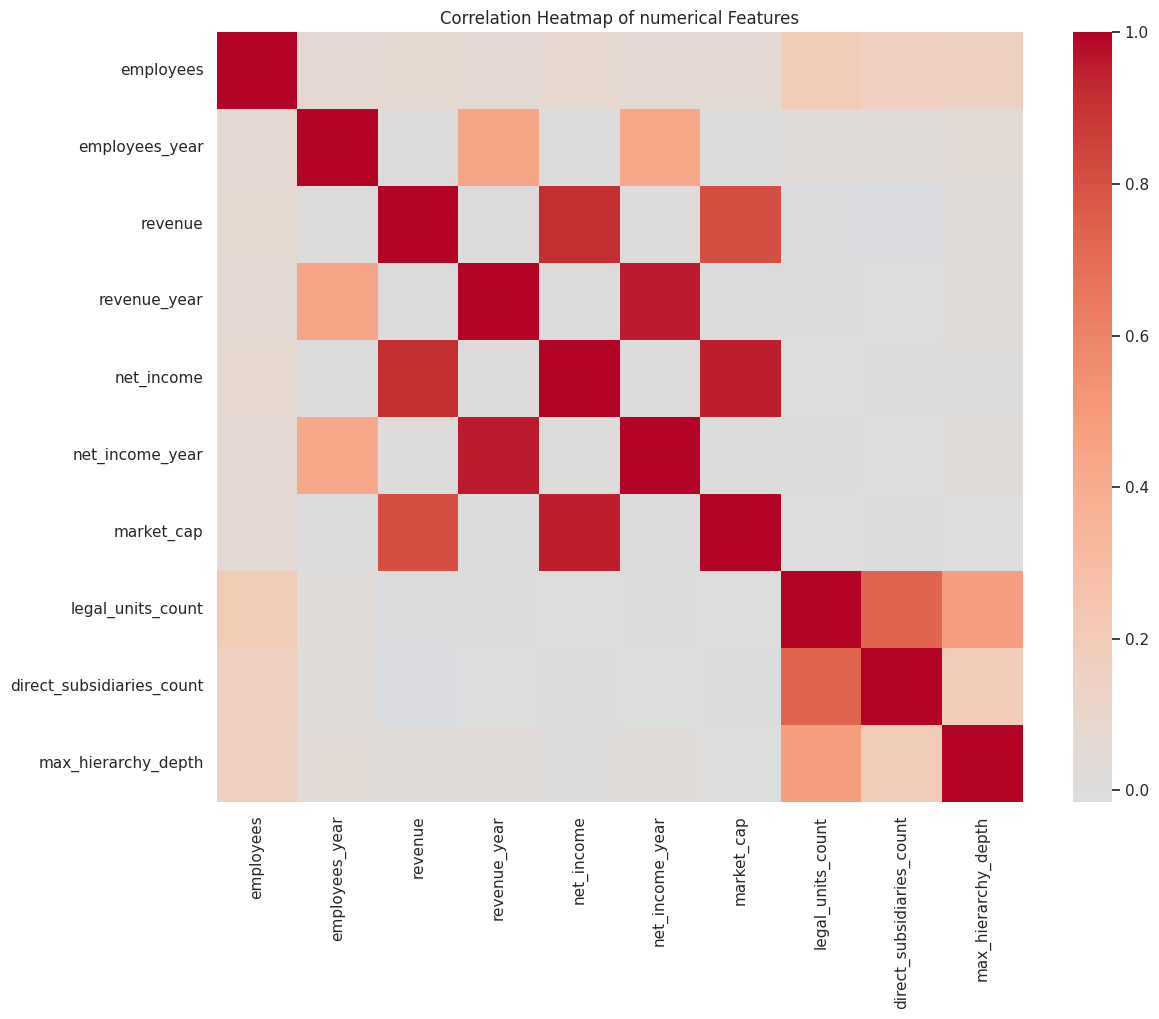

,Correlation with Revenue
revenue,1.000000
net_income,0.917533
market_cap,0.802694
employees,0.070970
max_hierarchy_depth,0.016961
net_income_year,0.014795
revenue_year,0.013849
employees_year,0.010981
legal_units_count,-0.011279
direct_subsidiaries_count,-0.015666


In [334]:
corr = df[numerical_cols].corr(numeric_only=True)

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of numerical Features")
plt.show()

display(corr[TARGET].sort_values(ascending=False).to_frame("Correlation with Revenue"))

Task 3 - Exploartory Data Analysis

1.Positive relationship between employee count and enterprise revenue.

2.Market capitalization may appear strongest predictors of revenue thus influences revenue

In [335]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [336]:
df.isnull().sum()

,0
enterprise_group_id,0
display_name,0
enterprise_group_name,0
group_root_lei,0
enterprise_group_jurisdiction,0
enterprise_group_entity_status,0
website,39
company_type,2
employees,99
employees_year,100


In [337]:
selected_features = [
    "employees",
    "net_income",
    "market_cap",
    "legal_units_count",
    "direct_subsidiaries_count",
    "max_hierarchy_depth",
    "is_standalone_entity",
    "enterprise_group_jurisdiction",
    "company_type",
    "employees_year",
    "revenue_year",
    "net_income_year",
    "market_cap_date"
]

selected_features = [c for c in selected_features if c in df.columns]

X = df[selected_features].copy()
y = df[TARGET].copy()

valid = y.notna()
X = X.loc[valid].copy()
y = y.loc[valid].copy()

print("Selected features:")
print(selected_features)
print("\nX shape:", X.shape)
print("y shape:", y.shape)


Selected features:
['employees', 'net_income', 'market_cap', 'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth', 'is_standalone_entity', 'enterprise_group_jurisdiction', 'company_type', 'employees_year', 'revenue_year', 'net_income_year', 'market_cap_date']

X shape: (1654, 13)
y shape: (1654,)


In [338]:
if "market_cap_date" in X.columns:
    X["market_cap_date"] = pd.to_datetime(X["market_cap_date"], errors="coerce")
    X["market_cap_date_year"] = X["market_cap_date"].dt.year
    X["market_cap_date_month"] = X["market_cap_date"].dt.month
    X["market_cap_date_day"] = X["market_cap_date"].dt.day
    X.drop(columns=["market_cap_date"], inplace=True)

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Final numerical features:", num_features)
print("Final categorical features:", cat_features)

Final numerical features: ['employees', 'net_income', 'market_cap', 'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth', 'employees_year', 'revenue_year', 'net_income_year', 'market_cap_date_year', 'market_cap_date_month', 'market_cap_date_day']
Final categorical features: ['is_standalone_entity', 'enterprise_group_jurisdiction', 'company_type']


In [339]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])


Training rows: 1323
Testing rows : 331


In [340]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_features),
        ("cat", categorical_transformer, cat_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


Task 2 - Data Preprocessing

1.The important preprocessing steps were missing-value treatment, outlier handling, categorical encoding, feature selection, and scaling . Missing values can reduce the quality of predictions, Categorical variables must be converted into numerical form for better predictions

2.Models generally require numerical input. Variables such as jurisdiction, company type, or industry category contain text values.They  cannot be directly processed by most mathematical algorithms. Encoding converts these categories into numerical representations.

In [341]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}
print("Models:", list(models.keys()))

Models: ['Linear Regression', 'Random Forest', 'Extra Trees', 'Gradient Boosting']


In [342]:
results = []
trained_models = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    trained_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
display(results_df)


,Model,MAE,RMSE,R2
1,Random Forest,4.998231e+11,3.373926e+12,0.862142
3,Gradient Boosting,5.570384e+11,3.542218e+12,0.848046
0,Linear Regression,7.629201e+11,4.571246e+12,0.746936
2,Extra Trees,6.149210e+11,4.733433e+12,0.728660


In [343]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]



In [344]:
best_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, best_pred)
rmse = np.sqrt(mean_squared_error(y_test, best_pred))
r2 = r2_score(y_test, best_pred)
print("Best Model:", best_model_name)
print(f"MAE  = {mae:,.2f}")
print(f"RMSE = {rmse:,.2f}")
print(f"R²   = {r2:.4f}")


Best Model: Random Forest
MAE  = 499,823,064,438.25
RMSE = 3,373,926,212,797.99
R²   = 0.8621


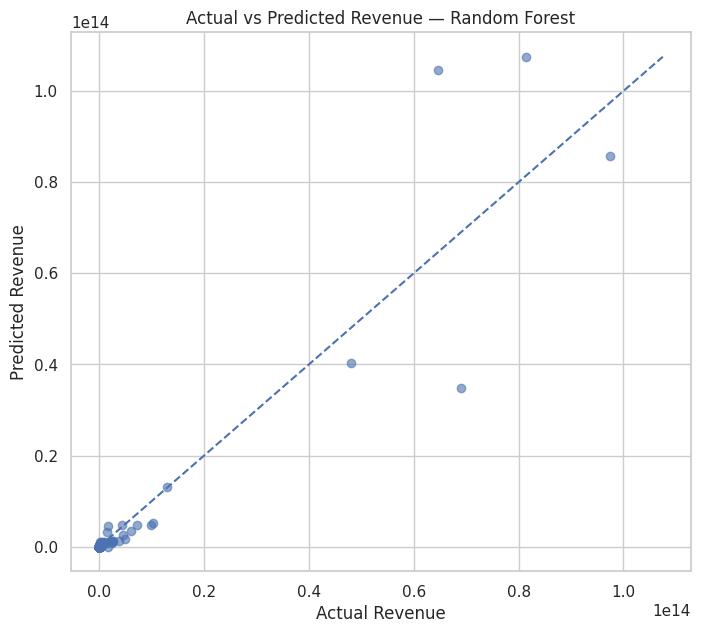

In [345]:
plt.figure(figsize=(8, 7))
plt.scatter(y_test, best_pred, alpha=0.6)

min_value = min(y_test.min(), best_pred.min())
max_value = max(y_test.max(), best_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title(f"Actual vs Predicted Revenue — {best_model_name}")
plt.show()


Task 4 - Regression Model

1.Random tree performed the best,because the model has a good r2-score.

In [346]:
MODEL_FILE = "revenue_model.pkl"
joblib.dump(best_model, MODEL_FILE)

print("Saved:", MODEL_FILE)


Saved: revenue_model.pkl


In [347]:
from google.colab import files

files.download('revenue_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>